# Questionnaires — Flow and Load Compare

Violin plots for FSS2/FSS (main figure) and IMI/RSME/frust (supplementary).

**Toggles:** `PAPER` and `PARADIGM`


In [40]:
from datetime import datetime
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

sns.set_theme()
plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 13,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',
})

def find_repo_root(marker="core") -> Path:
    """Walk up from the current directory until a folder containing
    `marker` (e.g. core/) is found -- avoids hardcoding folder depth,
    which breaks every time notebooks get moved."""
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / marker).is_dir():
            return candidate
    raise RuntimeError(f"Could not locate repo root (no '{marker}/' found above {Path.cwd()})")

sys.path.insert(0, str(find_repo_root() / 'core'))
from participants import get_participants


# ==============================================================================
# CONFIGURATION
# ==============================================================================

PAPER    = "flow"    # "flow" | "load"
PARADIGM = "active"  # "active" | "passive"

DATE_STR  = datetime.today().strftime("%Y%m%d")
STUDY     = "Active" if PARADIGM == "active" else "Passive"

if sys.platform == "win32":
    root_data = Path(f"L:/EEG_Flow_data/Study_EEG_Flow_{STUDY}/derivatives_v2/outputs/measures/behavior")
    root_img  = Path(f"L:/EEG_Flow_data/Study_EEG_Flow_{STUDY}/derivatives_v2/outputs/img/{PAPER}/behavior")
else:
    root_data = Path(f"/Volumes/faculty/EEG_Flow_data/Study_EEG_Flow_{STUDY}/derivatives_v2/outputs/measures/behavior")
    root_img  = Path(f"/Volumes/faculty/EEG_Flow_data/Study_EEG_Flow_{STUDY}/derivatives_v2/outputs/img/{PAPER}/behavior")

root_img.mkdir(parents=True, exist_ok=True)

DATE_SOURCE = "20261016"

print(f"Paper: {PAPER.upper()} | Paradigm: {PARADIGM.upper()}")


Paper: FLOW | Paradigm: ACTIVE


In [41]:
# ==============================================================================
# Load data
# ==============================================================================

fname = root_data / f"{DATE_SOURCE}_{PARADIGM}_questionnaires.csv"
df_all = pd.read_csv(fname)
print(f"Loaded: {len(df_all)} rows | {df_all['participant'].nunique()} participants")
print(f"Measures: {sorted(df_all['measure'].unique())}")

# Filter to included participants
included = list(get_participants(PAPER, PARADIGM).keys())
df_all   = df_all[df_all["participant"].isin(included)]
n        = df_all["participant"].nunique()
print(f"After filter: {n} participants")


Loaded: 4560 rows | 76 participants
Measures: ['FSS2_1_CSB', 'FSS2_2_MAA', 'FSS2_3_CC', 'FSS2_4_UF', 'FSS2_5_CTH', 'FSS2_6_SC', 'FSS2_7_LSC', 'FSS2_8_TT', 'FSS2_9_AE', 'FSS2_Agg3', 'FSS2_Agg6', 'FSS2_Global', 'IMI', 'RSME', 'frust']
After filter: 36 participants


In [42]:
# ==============================================================================
# Condition config — depends on paper
# ==============================================================================

if PAPER == "flow":
    CONDITIONS  = ["High Flow", "Low Flow"]
    MY_PAL      = {"High Flow": "#E74C3C", "Low Flow": "#2ECC71"}
    FSS_PREFIX  = "FSS2" if PARADIGM == "active" else "FSS"
    GLOBAL_MEAS = f"{FSS_PREFIX}_Global"
    AGG6_MEAS   = f"{FSS_PREFIX}_Agg6"
    TITLE_GLOBAL = f"{FSS_PREFIX}: across all 9 dimensions"
    TITLE_AGG6   = f"{FSS_PREFIX}-6: 6 subjective dimensions"
    HYPOTHESIS   = {"IMI": "higher", "frust": "lower", "RSME": "lower"}

else:  # load
    CONDITIONS  = ["Simple", "Complex"]
    MY_PAL      = {"Simple": "#3498DB", "Complex": "#F39C12"}
    FSS_PREFIX  = "FSS2" if PARADIGM == "active" else "FSS"
    GLOBAL_MEAS = f"{FSS_PREFIX}_Global"
    AGG6_MEAS   = f"{FSS_PREFIX}_Agg6"
    TITLE_GLOBAL = f"{FSS_PREFIX}: across all 9 dimensions"
    TITLE_AGG6   = f"{FSS_PREFIX}-6: 6 subjective dimensions"
    HYPOTHESIS   = {"IMI": "higher", "frust": "lower", "RSME": "lower"}

palette = {
    "Oddball only": "#AAAAAA",
    "High Flow":    "#E74C3C",
    "Low Flow":     "#2ECC71",
}

# Filter to oddball_game task only
df_game = df_all[df_all["task"] == "oddball_game"].copy()

# Map condition labels for load
if PAPER == "load":
    df_compare = df_all.copy()
    df_compare["condition"] = df_compare["condition"].map({
        "AudioOnly1": "Simple",
        "AudioOnly2": "Simple",
        "Low Flow":   "Complex",
        "High Flow":  "Complex",
    })
else:
    df_compare = df_game.copy()

# Average across blocks per participant x condition
df_avg = (
    df_compare[df_compare["condition"].isin(CONDITIONS)]
    .groupby(["participant", "condition", "measure"])["score"]
    .mean()
    .reset_index()
)

print(f"Conditions: {sorted(df_avg['condition'].unique())}")
print(f"N participants in game task: {df_avg['participant'].nunique()}")


Conditions: ['High Flow', 'Low Flow']
N participants in game task: 36


In [43]:
# ==============================================================================
# Helper: violin plot with paired lines
# ==============================================================================

COLOR_CONFIRMS = "#2196F3"
COLOR_VIOLATES = "#FF9800"
COLOR_EQUAL    = "#BDBDBD"
# Should match Fig 4's settled palette
COLOR_CONFIRMS = "#9E9E9E"
COLOR_VIOLATES = "#F0A500"
COLOR_EQUAL    = COLOR_CONFIRMS

# def violin_paired(ax, data, measure, conditions, palette, hypothesis=None,
#                   ylim=None, ytick=None, title="", ylabel="Score",
#                   participant_col="participant"):
    
#     sns.violinplot(
#         data=data, x="condition", y="score",
#         palette=palette, order=conditions,
#         cut=0, inner="quart", ax=ax, split=False,
#     )
#     if ylim:  ax.set_ylim(ylim)
#     if ytick: ax.yaxis.set_major_locator(ticker.MultipleLocator(ytick))

#     count_confirms = count_violates = count_equal = 0
#     expected = hypothesis.get(measure) if hypothesis else None

#     for p in data[participant_col].unique():
#         pdata = data[
#             (data[participant_col] == p) &
#             (data["condition"].isin(conditions))
#         ]
#         if len(pdata) == 2:
#             scores = pdata.set_index("condition").loc[conditions, "score"].values
#             v1, v2 = scores[0], scores[1]
#             if expected is None:
#                 color = "#888888"
#             elif v1 == v2:
#                 color = COLOR_EQUAL;    count_equal    += 1
#             elif (expected == "higher" and v1 > v2) or (expected == "lower" and v1 < v2):
#                 color = COLOR_CONFIRMS; count_confirms += 1
#             else:
#                 color = COLOR_VIOLATES; count_violates += 1
#             ax.plot([0, 1], scores, marker="o", linestyle="-",
#                     color=color, alpha=0.65, linewidth=1.2)

#     ax.set_xlabel("")
#     ax.set_ylabel(ylabel)
#     ax.set_title(title)
#     ax.set_xticklabels(conditions, fontweight='bold')
#     return count_confirms, count_violates, count_equal

def violin_paired(ax, data, measure, conditions, palette, hypothesis=None,
                  ylim=None, ytick=None, title="", ylabel="Score",
                  participant_col="participant", color_code=None):
    """
    color_code: True  = color lines by confirms/violates/equal (current behavior).
                False = draw all paired lines in a single neutral gray,
                        regardless of hypothesis direction.
                None (default) = auto: True if PAPER == "flow", False if PAPER == "load".
    """
    if color_code is None:
        color_code = (PAPER == "flow")

    sns.violinplot(
        data=data, x="condition", y="score",
        palette=palette, order=conditions,
        cut=0, inner="quart", ax=ax, split=False,
    )
    if ylim:  ax.set_ylim(ylim)
    if ytick: ax.yaxis.set_major_locator(ticker.MultipleLocator(ytick))

    count_confirms = count_violates = count_equal = 0
    expected = hypothesis.get(measure) if hypothesis else None

    for p in data[participant_col].unique():
        pdata = data[
            (data[participant_col] == p) &
            (data["condition"].isin(conditions))
        ]
        if len(pdata) == 2:
            scores = pdata.set_index("condition").loc[conditions, "score"].values
            v1, v2 = scores[0], scores[1]

            # Counts are always computed -- even with color_code=False, you
            # still get confirms/violates/equal back for reporting, just
            # without the visual distinction on the plot itself.
            if expected is None:
                status = None
            elif v1 == v2:
                status = "equal";    count_equal    += 1
            elif (expected == "higher" and v1 > v2) or (expected == "lower" and v1 < v2):
                status = "confirms"; count_confirms += 1
            else:
                status = "violates"; count_violates += 1

            if not color_code:
                color = COLOR_EQUAL          # single neutral gray, no distinction
            elif status == "equal":
                color = COLOR_EQUAL
            elif status == "confirms":
                color = COLOR_CONFIRMS
            elif status == "violates":
                color = COLOR_VIOLATES
            else:
                color = "#888888"            # no hypothesis supplied at all

            ax.plot([0, 1], scores, marker="o", linestyle="-",
                    color=color, alpha=0.65, linewidth=1.2)

    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticklabels(conditions, fontweight='bold')
    return count_confirms, count_violates, count_equal

print("Helper ready.")


Helper ready.


In [44]:
print(CONDITIONS)  # doit être ["Simple", "Complex"] pour que Simple soit à gauche

['High Flow', 'Low Flow']


Saved -> 20261016_active_flow_fss_main


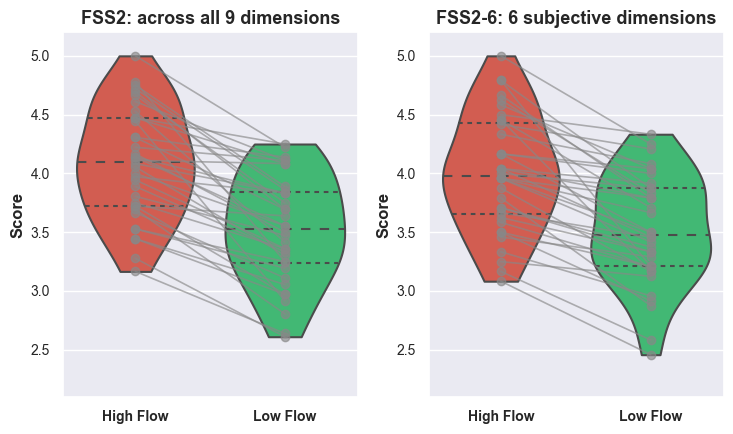

In [45]:
AUTO_YLIM = False   # True = auto scale | False = use fixed ylim below
FSS_YLIM  = (2.1, 5.2)  # used only if AUTO_YLIM = False

# ==============================================================================
# Main figure: FSS Global + Agg6
# ==============================================================================

sns.set_style("darkgrid")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.5, 4.5))

for ax, measure, title in [
    (ax1, GLOBAL_MEAS, TITLE_GLOBAL),
    (ax2, AGG6_MEAS,   TITLE_AGG6),
]:
    df_m = df_avg[df_avg["measure"] == measure]
    violin_paired(ax, df_m, measure, CONDITIONS, MY_PAL,
                  ylim=None if AUTO_YLIM else FSS_YLIM, 
                  title=title, ylabel="Score")
    
# plt.suptitle(f"{FSS_PREFIX} — {PARADIGM.capitalize()} | N={n}", fontsize=11)
plt.tight_layout()

fname_main = root_img / f"{DATE_STR}_{PARADIGM}_{PAPER}_fss_main"

plt.savefig(f"{fname_main}.svg", dpi=600, bbox_inches="tight")
plt.savefig(f"{fname_main}.pdf", dpi=600, bbox_inches="tight")

print(f"Saved -> {fname_main.name}")
plt.show()


Saved -> 20261016_active_flow_supp_questionnaires


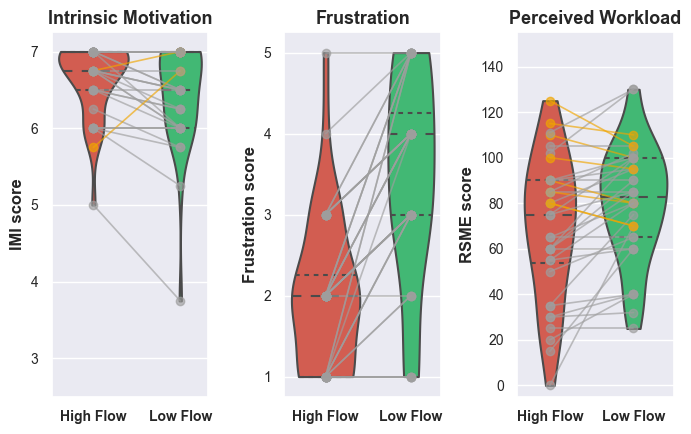

In [46]:
AUTO_YLIM = False   # True = auto scale | False = use fixed ylim below

# ==============================================================================
# Supplementary: IMI, RSME, frust
# ==============================================================================

SUPP_MEASURES = {
    "IMI":   {"label": "Intrinsic Motivation", "ylabel": "IMI score",
              "ylim": None if AUTO_YLIM else (2.5, 7.25), "ytick": 1},
    "frust": {"label": "Frustration",          "ylabel": "Frustration score",
              "ylim": None if AUTO_YLIM else (0.75, 5.25), "ytick": 1},
    "RSME":  {"label": "Perceived Workload",   "ylabel": "RSME score",
              "ylim": None if AUTO_YLIM else (-5, 155), "ytick": 20},
}

fig, axes = plt.subplots(1, 3, figsize=(7, 4.5))

for ax, (measure, cfg) in zip(axes, SUPP_MEASURES.items()):
    df_m = df_avg[df_avg["measure"] == measure]
    c, v, e = violin_paired(
        ax, df_m, measure, CONDITIONS, MY_PAL,
        hypothesis = HYPOTHESIS,
        ylim       = cfg["ylim"],
        ytick      = cfg["ytick"],
        title      = cfg["label"],
        ylabel     = cfg["ylabel"],
    )

# plt.suptitle(f"Supplementary — {PARADIGM.capitalize()} | N={n}", fontsize=10)
plt.tight_layout()

fname_supp = root_img / f"{DATE_STR}_{PARADIGM}_{PAPER}_supp_questionnaires"

plt.savefig(f"{fname_supp}.svg", dpi=600, bbox_inches="tight")
plt.savefig(f"{fname_supp}.pdf", dpi=600, bbox_inches="tight")
print(f"Saved -> {fname_supp.name}")
plt.show()


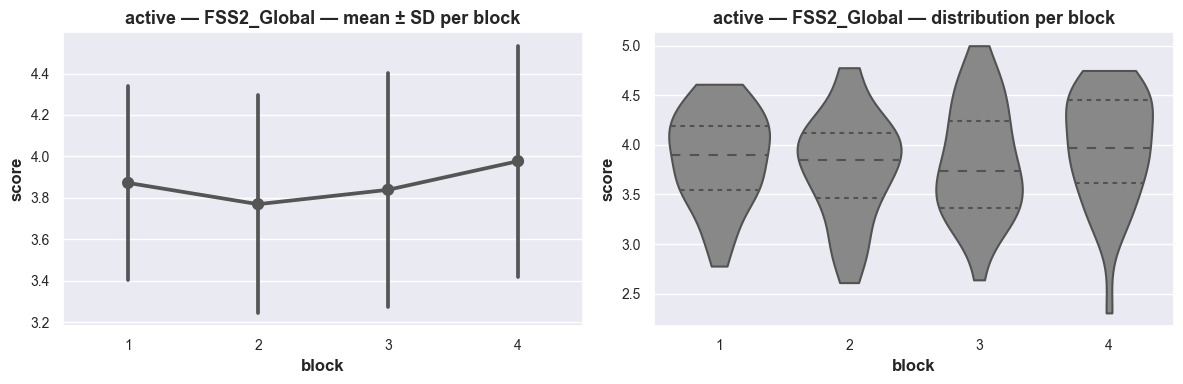

Saved -> 20261016_active_temporal_FSS2_Global.svg


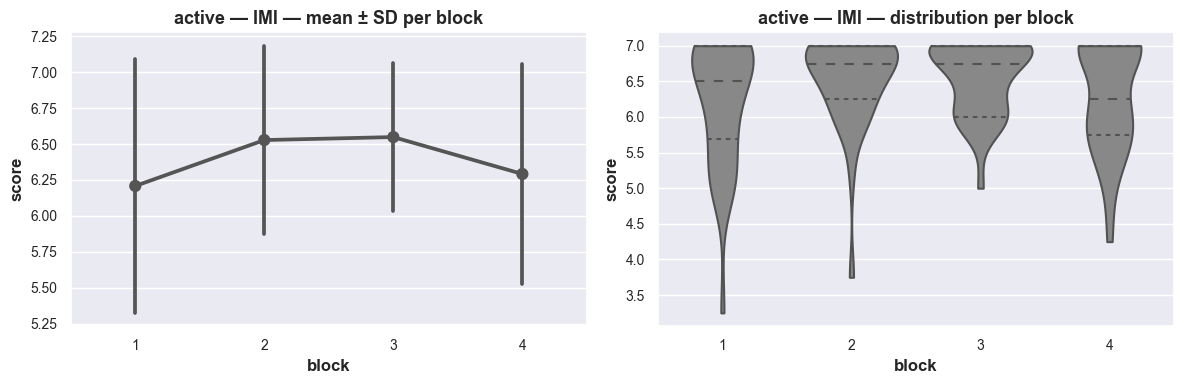

Saved -> 20261016_active_temporal_IMI.svg


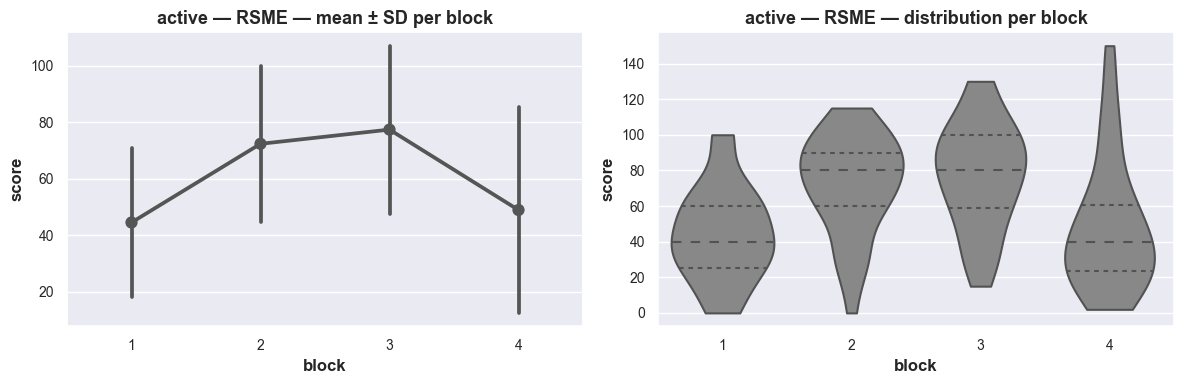

Saved -> 20261016_active_temporal_RSME.svg


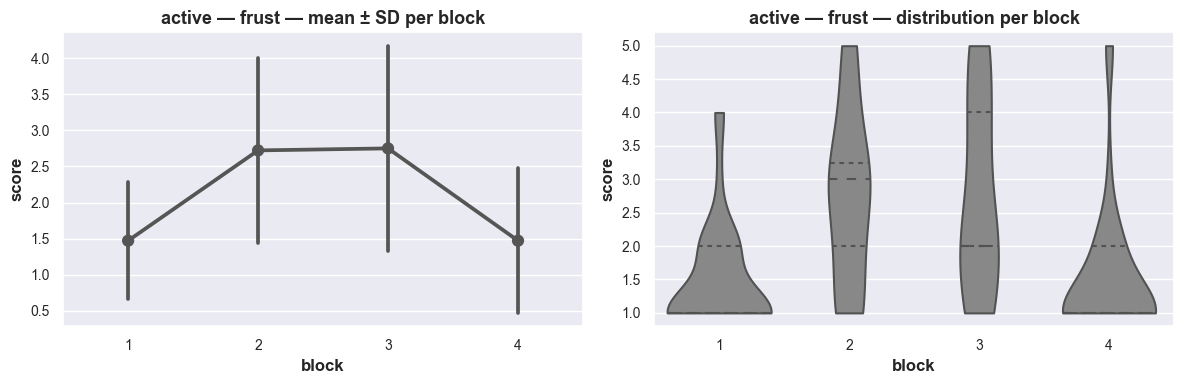

Saved -> 20261016_active_temporal_frust.svg


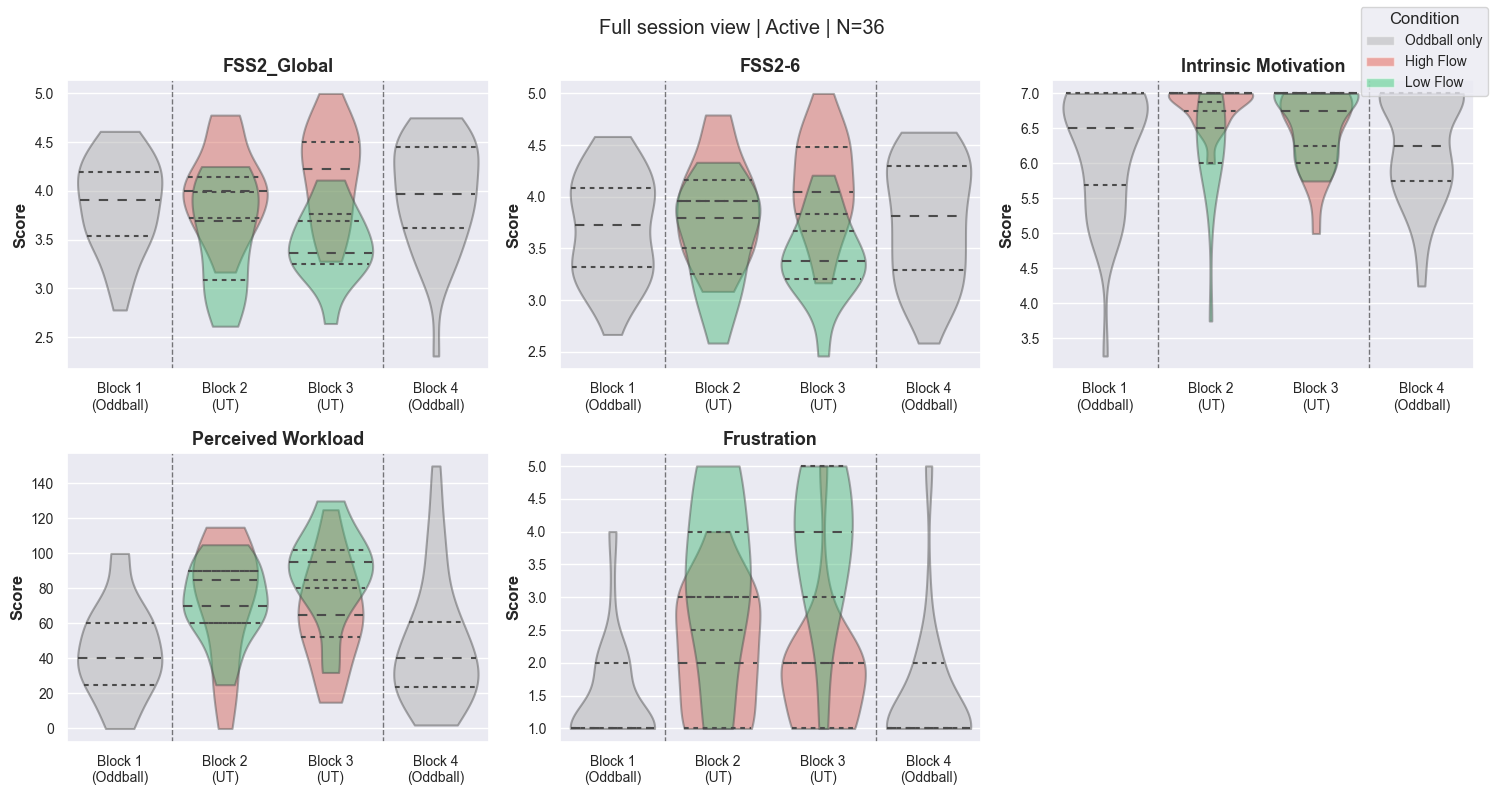

Saved -> 20261016_active_temporal_all_blocks_all_measures.svg


In [47]:
# ==============================================================================
# Optional: temporal view — scores across blocks (session order)
# Not paper-specific — shows all 4 blocks regardless of PAPER toggle
# ==============================================================================

SHOW_TEMPORAL = True

root_img_behavior = (
    Path(f'L:/EEG_Flow_data/Study_EEG_Flow_{STUDY}/derivatives_v2/outputs/img/temporal_behavior')
    if sys.platform == 'win32' else
    Path(f'/Volumes/faculty/EEG_Flow_data/Study_EEG_Flow_{STUDY}/derivatives_v2/outputs/img/temporal_behavior')
)
root_img_behavior.mkdir(parents=True, exist_ok=True)

if SHOW_TEMPORAL:
    # --- per-measure: pointplot + violin ---
    for measure in [GLOBAL_MEAS, 'IMI', 'RSME', 'frust']:
        df_m = df_all[df_all['measure'] == measure].copy()

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

        sns.pointplot(data=df_m, x='block', y='score',
                      errorbar='sd', ax=ax1, color='#555555')
        ax1.set_title(f'{PARADIGM} — {measure} — mean ± SD per block')

        sns.violinplot(data=df_m, x='block', y='score',
                       cut=0, inner='quart', ax=ax2, color='#888888')
        ax2.set_title(f'{PARADIGM} — {measure} — distribution per block')

        plt.tight_layout()

        fname = root_img_behavior / f'{DATE_STR}_{PARADIGM}_temporal_{measure.replace("/", "-")}.svg'
        plt.savefig(fname, dpi=300, bbox_inches='tight')
        plt.show()
        print(f'Saved -> {fname.name}')

    # --- combined: all measures in one figure ---
    palette = {'Oddball only': '#AAAAAA', 'High Flow': '#E74C3C', 'Low Flow': '#2ECC71'}

    measures_temporal = [GLOBAL_MEAS, AGG6_MEAS, 'IMI', 'RSME', 'frust']
    titles_temporal   = [GLOBAL_MEAS, f'{FSS_PREFIX}-6',
                         'Intrinsic Motivation', 'Perceived Workload', 'Frustration']

    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.flatten()

    for ax, measure, title in zip(axes, measures_temporal, titles_temporal):
        df_m = df_all[df_all['measure'] == measure].copy()
        df_m['condition_label'] = df_m['condition'].map({
            'AudioOnly1': 'Oddball only',
            'AudioOnly2': 'Oddball only',
            'High Flow':  'High Flow',
            'Low Flow':   'Low Flow',
        })

        sns.violinplot(
            data=df_m, x='block', y='score',
            hue='condition_label', palette=palette,
            cut=0, inner='quart', ax=ax, dodge=False,
        )

        for patch in ax.collections:
            patch.set_alpha(0.45)

        ax.axvline(x=0.5, color='black', linestyle='--', linewidth=1, alpha=0.5)
        ax.axvline(x=2.5, color='black', linestyle='--', linewidth=1, alpha=0.5)

        ax.set_xticks([0, 1, 2, 3])
        ax.set_xticklabels(['Block 1\n(Oddball)', 'Block 2\n(UT)',
                            'Block 3\n(UT)', 'Block 4\n(Oddball)'])
        ax.set_xlabel('')
        ax.set_ylabel('Score')
        ax.set_title(title)
        ax.get_legend().remove()

    # hide unused subplot (5 measures, 6 axes)
    axes[-1].set_visible(False)

    from matplotlib.patches import Patch
    fig.legend(handles=[
        Patch(facecolor='#AAAAAA', alpha=0.45, label='Oddball only'),
        Patch(facecolor='#E74C3C', alpha=0.45, label='High Flow'),
        Patch(facecolor='#2ECC71', alpha=0.45, label='Low Flow'),
    ], loc='upper right', title='Condition')

    plt.suptitle(f'Full session view | {PARADIGM.capitalize()} | N={n}')
    plt.tight_layout()

    fname = root_img_behavior / f'{DATE_STR}_{PARADIGM}_temporal_all_blocks_all_measures.svg'
    plt.savefig(fname, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved -> {fname.name}')